# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | Telco Customer Churn (клиенты телеком-компании, IBM): [CSV по прямой ссылке](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv) |
| что значит одна строка | один клиент компании: какими услугами пользуется, какой у него договор, сколько платит и ушёл ли он |
| цель (столбец) | `Churn`: ушёл ли клиент (Yes превращаем в 1, No в 0) |
| тип задачи | классификация |
| метрика | доля верных ответов (`accuracy`); её надо сравнивать с пустышкой «никто не уйдёт» (73,5%), поэтому дополнительно смотрим, какую долю ушедших модель находит (recall) |
| кому и зачем нужен такой прогноз | отделу удержания клиентов: заранее найти тех, кто может уйти, и предложить им скидку или другой договор, пока клиент ещё не ушёл |

In [2]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
TARGET = "Churn"

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [3]:
raw = load_csv(DATA_URL, "telco")
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
passport(raw)

,тип,пропусков,"доля, %",разных,пример
customerID,object,0,0.0,7043,7590-VHVEG
gender,object,0,0.0,2,Female
SeniorCitizen,int64,0,0.0,2,0
Partner,object,0,0.0,2,Yes
Dependents,object,0,0.0,2,No
tenure,int64,0,0.0,73,1
PhoneService,object,0,0.0,2,No
MultipleLines,object,0,0.0,3,No phone service
InternetService,object,0,0.0,3,DSL
OnlineSecurity,object,0,0.0,3,No


In [5]:
print(raw[TARGET].value_counts())
print((raw[TARGET].value_counts(normalize=True) * 100).round(1))

df = raw.copy()
df[TARGET] = (df[TARGET] == "Yes").astype(int)   # Yes -> 1, No -> 0
log("загрузка", f"строк: {raw.shape[0]}, столбцов: {raw.shape[1]} (CSV по ссылке)", len(df))
log("цель в 0 и 1", "Churn: Yes -> 1, No -> 0", len(df))
print("доля ушедших:", round(df[TARGET].mean() * 100, 1), "%")

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64
доля ушедших: 26.5 %


**Вывод.** В таблице 7 043 строки и 21 столбец, 18 из них текстовые. В паспорте видна главная проблема: `TotalCharges` прочитан как текст, хотя это сумма денег (раздел 3 покажет почему). `customerID` разный у каждой строки: это номер клиента, а не признак, в модель он не пойдёт. Пропусков по `isna()` нет, но скрытый пропуск есть, о нём ниже. Цель `Churn`: ушли 1 869 клиентов (26,5%), остались 5 174 (73,5%). Классы не поровну, поэтому пустышка «все останутся» уже даёт 73,5%: именно эту планку модель должна побить. Цель переведена в 0 и 1 и записана в журнал.

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [6]:
print("полных дублей:", raw.duplicated().sum())
print("повторов customerID:", raw["customerID"].duplicated().sum())

# строки, которые совпадают во всех столбцах, кроме номера клиента
no_id = raw.drop(columns="customerID")
n_same = int(no_id.duplicated().sum())
same = raw[no_id.duplicated(keep=False)].sort_values(list(no_id.columns))
print("лишних копий без учёта customerID:", n_same, "| строк в таких группах:", len(same))
same.head(6)

полных дублей: 0
повторов customerID: 0
лишних копий без учёта customerID: 22 | строк в таких группах: 42


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6491,9728-FTTVZ,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
6764,7660-HDPJV,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
4495,4702-IOQDC,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
6267,0328-GRPMV,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
5522,2619-WFQWU,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes
5759,9985-MWVIX,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes


In [7]:
df = df.drop_duplicates(subset="customerID")   # повторов номера нет, строки не удаляются
log("дубли", f"полных дублей и повторов customerID нет; без учёта номера совпадают {n_same} строк, но это разные клиенты: оставляем", len(df))
print(len(df))

7043


**Вывод.** Полных дублей 0, повторов `customerID` тоже 0. Если не смотреть на номер клиента, 22 строки повторяют другую строку целиком (одинаковые услуги, договор, срок и платежи). Это не ошибка выгрузки: у каждой строки свой `customerID`, а при 20 столбцах в основном с категориями «Yes/No» разные люди легко совпадают. Удалять не стал: потерял бы настоящих клиентов. Решение: оставить все 7 043 строки.

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [8]:
def check_rules(d):
    """Таблица флагов: True там, где строка нарушает правило."""
    tc = pd.to_numeric(d["TotalCharges"], errors="coerce")
    ratio = tc / (d["tenure"] * d["MonthlyCharges"])      # сколько заплатил / сколько должен был при текущей цене
    return pd.DataFrame({
        "tenure < 0": d["tenure"] < 0,
        "MonthlyCharges <= 0": d["MonthlyCharges"] <= 0,
        "TotalCharges < 0": tc < 0,
        "TotalCharges > 0 при tenure = 0": (d["tenure"] == 0) & (tc > 0),
        "TotalCharges отличается от tenure * MonthlyCharges в 2 раза": (ratio < 0.5) | (ratio > 2),
        "нет телефона, но MultipleLines не 'No phone service'": (d["PhoneService"] == "No") != (d["MultipleLines"] == "No phone service"),
        "нет интернета, но TechSupport не 'No internet service'": (d["InternetService"] == "No") != (d["TechSupport"] == "No internet service"),
    })

In [9]:
rules = check_rules(df)
print(rules.sum())
print("строк с любым нарушением:", int(rules.any(axis=1).sum()))

tc_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
ratio = (tc_num / (df["tenure"] * df["MonthlyCharges"])).dropna()
print("отношение TotalCharges к tenure * MonthlyCharges: от", round(ratio.min(), 2), "до", round(ratio.max(), 2))

tenure < 0                                                     0
MonthlyCharges <= 0                                            0
TotalCharges < 0                                               0
TotalCharges > 0 при tenure = 0                                0
TotalCharges отличается от tenure * MonthlyCharges в 2 раза    0
нет телефона, но MultipleLines не 'No phone service'           0
нет интернета, но TechSupport не 'No internet service'         0
dtype: int64
строк с любым нарушением: 0
отношение TotalCharges к tenure * MonthlyCharges: от 0.69 до 1.57


In [10]:
text_cols = [c for c in df.columns if c not in ("customerID", "TotalCharges") and not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    print(c, df[c].value_counts().to_dict())

print()
blank = df["TotalCharges"].str.strip() == ""
print("пробелов вместо числа в TotalCharges:", int(blank.sum()))
print(df.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", TARGET]])
print()
print(df.describe().round(2))

gender {'Male': 3555, 'Female': 3488}
Partner {'No': 3641, 'Yes': 3402}
Dependents {'No': 4933, 'Yes': 2110}
PhoneService {'Yes': 6361, 'No': 682}
MultipleLines {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling {'Yes': 4171, 'No': 2872}
PaymentMethod {'Electronic check': 2365, 'Mailed check': 1612, 'Bank transfer (automatic)': 1544, 'Credit card (automatic)': 1522}

пробелов вместо числа в TotalCharges: 11
      customerID  tenure

In [11]:
# пробел в TotalCharges это скрытый пропуск: превращаем его в настоящий NaN
df["TotalCharges"] = df["TotalCharges"].str.strip().replace("", np.nan)

log("невозможные значения", "7 правил здравого смысла, нарушений нет: ничего не удаляем и не исправляем", len(df))
log("скрытые пропуски", "TotalCharges: пробел у 11 клиентов с tenure = 0 -> NaN; 'No internet service' и 'No phone service' это настоящий ответ, а не пропуск", len(df))
print("пропусков в TotalCharges теперь:", int(df["TotalCharges"].isna().sum()))

пропусков в TotalCharges теперь: 11


**Вывод.** Проверил 7 правил: `tenure` и цены не отрицательные, `TotalCharges` не отрицательный и не больше нуля при `tenure = 0`, `TotalCharges` не расходится с `tenure × MonthlyCharges` больше чем в 2 раза (на деле от 0,69 до 1,57), `MultipleLines` согласован с `PhoneService`, а `TechSupport` с `InternetService`. Нарушений нет ни по одному правилу, поэтому ничего не удаляю. Скрытый пропуск один: у 11 клиентов в `TotalCharges` стоит пробел, и из-за него столбец прочитался как текст. Все 11 с `tenure = 0` (подключились только что). «No internet service» и «No phone service» не пропуски, а настоящий ответ «услуги нет»; ими займусь в разделе про категории. Пробел превращён в NaN, решение по нему в разделе 4.

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [12]:
missing = df.isna().sum()
print(missing[missing > 0])
print("всего пропусков в таблице:", int(missing.sum()))

TotalCharges    11
dtype: int64
всего пропусков в таблице: 11


In [13]:
# пропуск как информация: цель у строк с пропуском и без
miss = df["TotalCharges"].isna()
print(df.groupby(miss)[TARGET].agg(["mean", "size"]).round(3))
print()
print("tenure у строк с пропуском:", df.loc[miss, "tenure"].unique())
print("медиана TotalCharges у остальных:", pd.to_numeric(df["TotalCharges"], errors="coerce").median())

               mean  size
TotalCharges             
False         0.266  7032
True          0.000    11

tenure у строк с пропуском: [0]
медиана TotalCharges у остальных: 1397.475


In [14]:
# пропуск говорит о строке (клиент новый), поэтому сначала флаг, потом заполнение «нет» = 0
df["no_bill_yet"] = df["TotalCharges"].isna().astype(int)
df["TotalCharges"] = df["TotalCharges"].fillna("0")

log("пропуски", "TotalCharges у 11 новых клиентов (tenure = 0) это «нет»: счетов ещё не было -> 0, добавлен флаг no_bill_yet", len(df))
print("пропусков осталось:", int(df.isna().sum().sum()))

пропусков осталось: 0


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |
|---|---|---|---|---|
| TotalCharges | 11 (0,2%) | «нет» | заполняем 0 и добавляем флаг `no_bill_yet` | у всех 11 `tenure = 0`: клиент подключился только что, первый счёт не выставлен, сумма платежей на деле равна 0. Медиана (около 1 400) приписала бы новичкам платежи, которых не было |

**Вывод.** Во всей таблице пропуск только в одном столбце. Все 11 клиентов с `tenure = 0`, и ни один из них не ушёл (0% против 26,5% по таблице), так что пропуск говорит о строке: поставил флаг `no_bill_yet`. Заполнил нулём, а не медианой: это «нет», а не «не знаем». Строки не удаляю: их всего 11 из 7 043, но это настоящие клиенты, и удаление скрыло бы целый тип клиента (новичков).

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [15]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("пропусков после to_numeric:", int(df["TotalCharges"].isna().sum()))
log("типы", "TotalCharges: текст -> число (float)", len(df))
print(df.dtypes)

пропусков после to_numeric: 0
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
no_bill_yet           int64
dtype: object


In [16]:
date_like = [c for c in df.columns if "date" in c.lower() or "time" in c.lower()]
print("столбцов с датами:", date_like)
log("даты", "дат в данных нет: срок клиента записан числом месяцев tenure", len(df))

столбцов с датами: []


**Вывод.** Записан не так был один столбец: `TotalCharges` был текстом из-за пробелов, теперь это число (float) без пропусков. `SeniorCitizen` уже 0 и 1, `tenure` целое число месяцев. Дат в данных нет: срок обслуживания хранится числом месяцев, поэтому признаков из дат не будет. Текста с единицами («76%», «SR 1,385») тоже нет.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [17]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append({
        "столбец": c,
        "нижняя граница": round(low, 1), "верхняя граница": round(high, 1),
        "ниже": int((df[c] < low).sum()), "выше": int((df[c] > high).sum()),
        "минимум": round(df[c].min(), 1), "максимум": round(df[c].max(), 1),
        "99,9%": round(df[c].quantile(0.999), 1), "перекос": round(df[c].skew(), 2),
    })
pd.DataFrame(rows).set_index("столбец")

,нижняя граница,верхняя граница,ниже,выше,минимум,максимум,"99,9%",перекос
столбец,,,,,,,,
tenure,-60.0,124.0,0,0,0.0,72.0,72.0,0.24
MonthlyCharges,-46.0,171.4,0,0,18.2,118.8,117.6,-0.22
TotalCharges,-4683.5,8868.7,0,0,0.0,8684.8,8528.1,0.96


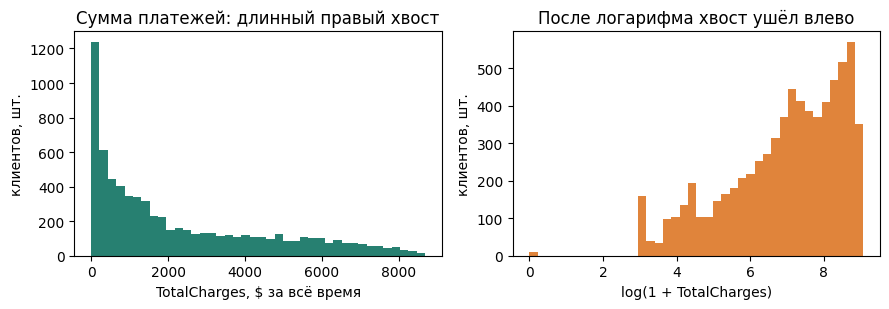

перекос до: 0.96 | после логарифма: -0.82


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(df["TotalCharges"], bins=40, color=TEAL)
axes[0].set_title("Сумма платежей: длинный правый хвост")
axes[0].set_xlabel("TotalCharges, $ за всё время")
axes[0].set_ylabel("клиентов, шт.")
axes[1].hist(np.log1p(df["TotalCharges"]), bins=40, color=ORANGE)
axes[1].set_title("После логарифма хвост ушёл влево")
axes[1].set_xlabel("log(1 + TotalCharges)")
axes[1].set_ylabel("клиентов, шт.")
plt.tight_layout()
plt.show()
print("перекос до:", round(df["TotalCharges"].skew(), 2), "| после логарифма:", round(np.log1p(df["TotalCharges"]).skew(), 2))

log("выбросы", "по IQR выбросов нет ни в tenure, ни в MonthlyCharges, ни в TotalCharges; длинный хвост TotalCharges это редкость, не ошибка: ничего не удаляем и не обрезаем", len(df))

**Вывод.** По правилу IQR выбросов нет ни в одном из трёх столбцов: максимум `tenure` 72 при границе 124, максимум `MonthlyCharges` 118,8 при границе 171, максимум `TotalCharges` 8 685 при границе 8 869. У `TotalCharges` длинный правый хвост (перекос 0,96): много новичков с маленькой суммой и мало старых клиентов с большой. Это редкость, а не ошибка: сумма растёт вместе с `tenure`, и крупный счёт у клиента с 72 месяцами нормален. Ничего не удаляю и не обрезаю. Логарифм перекос не убирает, а переворачивает (−0,82), поэтому оставляю исходную шкалу; для линейной модели признаки приведу к одному масштабу внутри `Pipeline`.

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

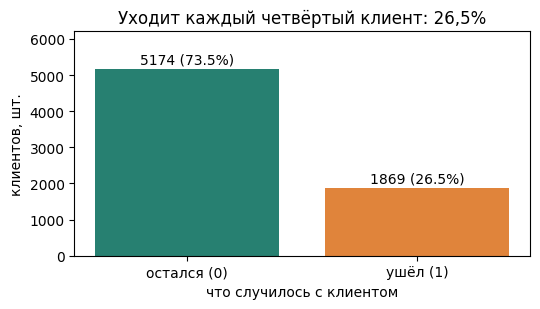

In [19]:
FIG = Path("figures")
FIG.mkdir(exist_ok=True)


def tp(groups, title, xlabel, fname):
    """target_plot из помощников + сохранение картинки в figures/ для README."""
    real_show = plt.show
    def show_and_save(*args, **kwargs):
        plt.gcf().savefig(FIG / fname, dpi=130, bbox_inches="tight")
        real_show(*args, **kwargs)
    plt.show = show_and_save
    try:
        return target_plot(df, groups, TARGET, title, xlabel)
    finally:
        plt.show = real_show


counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(["остался (0)", "ушёл (1)"], counts.values, color=[TEAL, ORANGE])
ax.bar_label(bars, labels=[f"{v} ({v / len(df) * 100:.1f}%)" for v in counts.values], padding=2)
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Уходит каждый четвёртый клиент: 26,5%")
ax.set_xlabel("что случилось с клиентом")
ax.set_ylabel("клиентов, шт.")
plt.tight_layout()
fig.savefig(FIG / "fig1_target.png", dpi=130, bbox_inches="tight")
plt.show()

**Что видно на графике 1.** Из 7 043 клиентов ушли 1 869 (26,5%), остались 5 174. Классы не поровну, поэтому одна лишь доля верных ответов обманчива: «все останутся» уже даёт 73,5%. Модель надо сравнивать именно с этой цифрой.

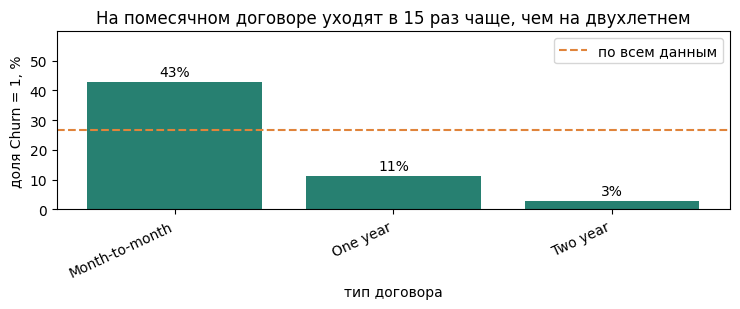

,mean,size
Contract,,
Month-to-month,0.427,3875
One year,0.113,1473
Two year,0.028,1695


In [20]:
tp(df["Contract"], "На помесячном договоре уходят в 15 раз чаще, чем на двухлетнем", "тип договора", "fig2_contract.png")

**Что видно на графике 2.** На помесячном договоре уходят 42,7% клиентов, на годовом 11,3%, на двухлетнем 2,8%. Тип договора один из самых сильных признаков: клиент без обязательств уходит легко, а долгий договор его удерживает.

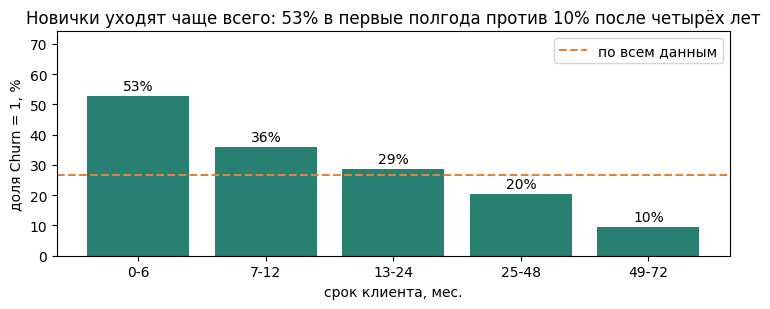

,mean,size
tenure,,
0-6,0.529,1481
7-12,0.359,705
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


In [21]:
tenure_bins = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
tp(tenure_bins, "Новички уходят чаще всего: 53% в первые полгода против 10% после четырёх лет", "срок клиента, мес.", "fig3_tenure.png")

**Что видно на графике 3.** В первые 6 месяцев уходит 52,9% клиентов (их 1 481), после 4 лет только 9,5% (2 239 клиентов). Риск быстро падает по мере того, как клиент задерживается: главный отток приходится на новичков.

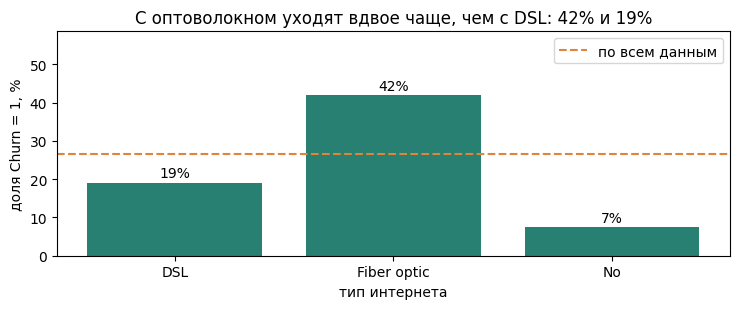

,mean,size
InternetService,,
DSL,0.190,2421
Fiber optic,0.419,3096
No,0.074,1526


In [22]:
tp(df["InternetService"], "С оптоволокном уходят вдвое чаще, чем с DSL: 42% и 19%", "тип интернета", "fig4_internet.png")

**Что видно на графике 4 (находка).** Fiber optic обычно самый дорогой и быстрый интернет, но именно с ним уходят чаще всего: 41,9% против 19,0% у DSL и 7,4% у клиентов без интернета. Парадокс: самая дорогая услуга хуже всего удерживает клиентов. Из этих данных причину не определить (цена, качество или конкуренты), но признак точно важный.

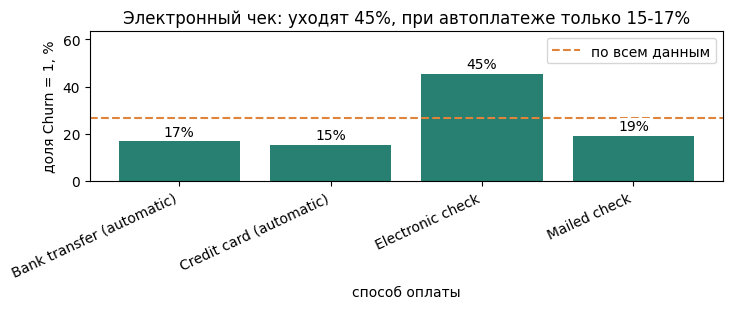

gender
Female    0.269
Male      0.262
Name: Churn, dtype: float64


In [23]:
tp(df["PaymentMethod"], "Электронный чек: уходят 45%, при автоплатеже только 15-17%", "способ оплаты", "fig5_payment.png")
print(df.groupby("gender")[TARGET].mean().round(3))

**Что видно на графике 5.** Среди платящих электронным чеком ушли 45,3%, среди платящих чеком по почте 19,1%, при автоплатеже банком и картой 16,7% и 15,2%. Автоплатёж связан с оттоком почти втрое меньшим. Это связь, а не причина: автоплатёж чаще подключают давние клиенты на долгих договорах. Для сравнения, пол клиента на отток почти не влияет: 26,9% у женщин и 26,2% у мужчин.

**Вывод по EDA.**

* Уходят 26,5% клиентов, поэтому пустышка «все останутся» даёт 73,5%.
* Сильнее всего с оттоком связан договор: 42,7% на помесячном против 2,8% на двухлетнем.
* Отток падает с ростом срока: 52,9% в первые полгода и 9,5% после четырёх лет.
* Парадокс: с оптоволокном уходят чаще (41,9%), чем с DSL (19,0%).
* Электронный чек сопровождается оттоком 45,3% против 15-17% при автоплатеже.
* Пол клиента почти не важен (26,9% и 26,2%).

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [24]:
def clean(raw_table):
    """Сырая таблица на входе, очищенная на выходе."""
    d = raw_table.copy()
    d[TARGET] = (d[TARGET] == "Yes").astype(int)                       # раздел 1: цель в 0 и 1
    d = d.drop_duplicates(subset="customerID")                          # раздел 2: повторов нет
    d["TotalCharges"] = d["TotalCharges"].str.strip().replace("", np.nan)   # раздел 3: пробел -> NaN
    d["no_bill_yet"] = d["TotalCharges"].isna().astype(int)             # раздел 4: флаг
    d["TotalCharges"] = d["TotalCharges"].fillna("0")                   # раздел 4: «нет» = 0
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")   # раздел 5: текст -> число
    return d                                                            # раздел 6: выбросов нет

In [25]:
clean_df = clean(raw)
print("clean(raw) совпадает с пошаговой очисткой:", clean_df.equals(df))

# сторожа
assert clean_df.equals(df), "clean даёт не ту таблицу, что пошаговая очистка"
assert clean_df.isna().sum().sum() == 0, "остались пропуски"
assert set(clean_df[TARGET].unique()) == {0, 1}, "цель не 0 и 1"
assert clean_df["customerID"].is_unique, "повторы customerID"
assert not check_rules(clean_df).any().any(), "остались невозможные значения"
assert pd.api.types.is_numeric_dtype(clean_df["TotalCharges"]), "TotalCharges не число"
assert len(clean_df) == len(raw), "потеряли строки"
print("все сторожа пройдены; размер:", clean_df.shape)

clean(raw) совпадает с пошаговой очисткой: True
все сторожа пройдены; размер: (7043, 22)


In [26]:
show_journal()

,решение,строк
загрузка,"строк: 7043, столбцов: 21 (CSV по ссылке)",7043
цель в 0 и 1,"Churn: Yes -> 1, No -> 0",7043
дубли,полных дублей и повторов customerID нет; без у...,7043
невозможные значения,"7 правил здравого смысла, нарушений нет: ничег...",7043
скрытые пропуски,TotalCharges: пробел у 11 клиентов с tenure = ...,7043
пропуски,TotalCharges у 11 новых клиентов (tenure = 0) ...,7043
типы,TotalCharges: текст -> число (float),7043
даты,дат в данных нет: срок клиента записан числом ...,7043
выбросы,"по IQR выбросов нет ни в tenure, ни в MonthlyC...",7043


In [27]:
Path("data").mkdir(exist_ok=True)
clean_df.to_csv("data/telco_clean.csv", index=False)
print("сохранено:", round(Path("data/telco_clean.csv").stat().st_size / 1024), "КБ")

сохранено: 954 КБ


**Вывод.** Одна функция `clean` проходит весь путь от сырой таблицы до чистой и даёт ровно ту же таблицу, что пошаговая очистка (`equals` даёт `True`): 7 043 строки, 22 столбца (добавился флаг `no_bill_yet`), пропусков нет. Сторожа проверяют: нет пропусков, цель только 0 и 1, `customerID` уникален, нарушений 7 правил нет, `TotalCharges` число, строки не потеряны. Журнал записан, чистый CSV лежит в `data/telco_clean.csv`.

---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [28]:
selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 7043, стало 7043; столбцов: было 21, стало 22


**Вывод самопроверки.** Все пункты `OK`: цель числовая и без пропусков, в чистой таблице нет пропусков и дублей, потерь строк нет, в журнале больше пяти решений.

**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

---
# Этап 2. Мидтерм, домашка занятия 12

Эти разделы заполняются после занятия 12, в этой же тетради и в том же репозитории. Здесь коротко, что в них будет. Подробности и баллы в ТЗ, примеры в частях 5, 7, 8 и 9 тетради практики занятия 11. Инструменты занятия 12 можно и нужно использовать.

## 10. Новые признаки

Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. У каждого одно предложение «зачем». Пример: часть 5, раздел 5.1.

In [29]:
# импорты этапа 2
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score

feat = clean_df.copy()
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

feat["n_addons"] = (feat[addons] == "Yes").sum(axis=1)
feat["avg_paid_per_month"] = feat["TotalCharges"] / feat["tenure"].clip(lower=1)
feat["price_change"] = feat["MonthlyCharges"] - feat["avg_paid_per_month"]
feat["has_family"] = ((feat["Partner"] == "Yes") | (feat["Dependents"] == "Yes")).astype(int)
feat["auto_pay"] = feat["PaymentMethod"].str.contains("automatic").astype(int)
feat["new_customer"] = (feat["tenure"] <= 6).astype(int)

new_features = ["n_addons", "price_change", "has_family", "auto_pay", "new_customer"]
print(feat.groupby(TARGET)[new_features].mean().round(2).T.rename(columns={0: "остался", 1: "ушёл"}))
print()
print("доля ушедших по n_addons:")
print(feat.groupby("n_addons")[TARGET].mean().round(3).to_dict())
log("новые признаки", "n_addons, avg_paid_per_month, price_change, has_family, auto_pay, new_customer", len(feat))

Churn         остался  ушёл
n_addons         2.14  1.77
price_change     0.08  0.01
has_family       0.58  0.40
auto_pay         0.50  0.26
new_customer     0.13  0.42

доля ушедших по n_addons:
{0: 0.214, 1: 0.458, 2: 0.358, 3: 0.274, 4: 0.223, 5: 0.124, 6: 0.053}


| признак | как считается | зачем |
|---|---|---|
| `n_addons` | сколько из 6 дополнительных услуг подключено | клиент с несколькими услугами крепче привязан к компании, чем клиент с одной базовой |
| `avg_paid_per_month` | `TotalCharges / tenure` (для новичков 1 месяц) | сколько клиент в среднем платил в месяц за всё время |
| `price_change` | `MonthlyCharges − avg_paid_per_month` | рост текущего платежа над привычным: подорожание может подтолкнуть к уходу |
| `has_family` | есть партнёр или иждивенцы | у клиентов с семьёй обычно больше причин не менять оператора |
| `auto_pay` | способ оплаты содержит «automatic» | автоплатёж связан с втрое меньшим оттоком (график 5), выделяю как отдельный флаг |
| `new_customer` | `tenure ≤ 6` месяцев | риск в первые полгода резко выше (график 3) |

**Вывод.** Добавил 5 признаков из смысла задачи плюс вспомогательный `avg_paid_per_month`. Все они известны в момент прогноза и считаются только из столбцов той же строки, поэтому утечки цели в них нет. У ушедших в среднем меньше `n_addons` (1,8 против 2,1), реже `auto_pay` (26% против 50%) и `has_family` (40% против 58%), и намного чаще `new_customer` (42% против 13%): признаки несут информацию. `price_change` почти не различает группы (0,01 против 0,08 $), так что он, скорее всего, слабый.

## 11. Категории

Редкие значения в `Other`, флаги через `get_dummies`. Итог: таблица признаков `X` только из чисел, без пропусков. Пример: часть 5, разделы 5.2-5.5.

In [30]:
def rare_to_other(s, min_share=0.05):
    """Значения, которых меньше min_share от всех строк, объединить в 'Other'."""
    share = s.value_counts(normalize=True)
    rare = share[share < min_share].index
    return s.where(~s.isin(rare), "Other")


multi = ["InternetService", "Contract", "PaymentMethod"]
for c in multi:
    print(c, (feat[c].value_counts(normalize=True) * 100).round(1).to_dict())
    feat[c] = rare_to_other(feat[c])
print("значений заменено на Other:", int(sum((feat[c] == "Other").sum() for c in multi)))

# «услуги нет» объединяем с «No»: сама информация о наличии телефона и интернета остаётся в PhoneService и InternetService
for c in addons + ["MultipleLines"]:
    feat[c] = feat[c].replace({"No internet service": "No", "No phone service": "No"})

yes_no = ["Partner", "Dependents", "PhoneService", "MultipleLines", "PaperlessBilling"] + addons
for c in yes_no:
    feat[c] = (feat[c] == "Yes").astype(int)
feat["is_male"] = (feat["gender"] == "Male").astype(int)

y = feat[TARGET]
X = feat.drop(columns=["customerID", TARGET, "gender"])
X = pd.get_dummies(X, columns=multi, drop_first=True, dtype=int)

assert X.select_dtypes(exclude="number").shape[1] == 0, "в X остался не числовой столбец"
assert X.isna().sum().sum() == 0, "в X остались пропуски"
print("X:", X.shape, "| типы:", X.dtypes.astype(str).value_counts().to_dict())
log("категории", "редких значений (меньше 5%) нет; Yes/No -> 1/0, 'No internet/phone service' -> No; get_dummies для InternetService, Contract, PaymentMethod; customerID и gender убраны/закодированы", len(X))

InternetService {'Fiber optic': 44.0, 'DSL': 34.4, 'No': 21.7}
Contract {'Month-to-month': 55.0, 'Two year': 24.1, 'One year': 20.9}
PaymentMethod {'Electronic check': 33.6, 'Mailed check': 22.9, 'Bank transfer (automatic)': 21.9, 'Credit card (automatic)': 21.6}
значений заменено на Other: 0
X: (7043, 30) | типы: {'int64': 26, 'float64': 4}


**Вывод.** Редких категорий в этих данных нет: самое редкое значение (годовой договор `One year`) занимает 20,9%, а порог редкости 5%, поэтому `rare_to_other` ничего не заменила, и это нормально. Остальное: «Yes/No» стали 1 и 0; «No internet service» и «No phone service» объединены с «No» (информация о наличии связи остаётся в `InternetService` и `PhoneService`); `InternetService`, `Contract` и `PaymentMethod` развёрнуты через `get_dummies(drop_first=True)`; `customerID` убран как номер. В `X` только числа и ни одного пропуска. Все преобразования строка-в-строку и не используют цель, так что утечки через них нет.

## 12. Утечка

Таблица «столбец, когда становится известен, берём или нет» для всех подозрительных столбцов. Проверка моделью хотя бы одного подозреваемого: насколько он поднимает качество. Пример: часть 7.

In [31]:
# делим сразу: все проверки и выбор моделей делаем кросс-валидацией на train, test не трогаем до раздела 13
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("train:", X_train.shape, "test:", X_test.shape)
log("разбиение", "train 80% / test 20%, stratify=y, random_state=42; решения принимаем кросс-валидацией на train, test трогаем один раз", len(X_train))

# проверка подозреваемых: что умеет предсказывать каждый из них в одиночку (дерево глубины 3)
assert clean_df["customerID"].str.match(r"^\d{4}-[A-Z]{5}$").all()
ids = clean_df["customerID"].str[:4].astype(int)      # цифровая часть номера клиента
suspects = pd.DataFrame({
    "customerID (4 цифры)": ids.loc[X_train.index],
    "tenure": X_train["tenure"],
    "TotalCharges": X_train["TotalCharges"],
    "MonthlyCharges": X_train["MonthlyCharges"],
})
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
leak_rows = {"пустышка (все останутся)": cross_val_score(DummyClassifier(strategy="most_frequent"), X_train, y_train, cv=cv).mean()}
for c in suspects.columns:
    leak_rows[c] = cross_val_score(tree, suspects[[c]], y_train, cv=cv).mean()
print("accuracy одного признака (кросс-валидация на train):")
print(pd.Series(leak_rows).round(3).to_string())

# модель целиком с подозреваемыми и без них
all_cols = list(X_train.columns)
suspect_cols = ["tenure", "TotalCharges", "avg_paid_per_month", "price_change", "new_customer"]
safe_cols = [c for c in all_cols if c not in suspect_cols]
lr = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
acc_all = cross_val_score(lr, X_train[all_cols], y_train, cv=cv).mean()
acc_safe = cross_val_score(lr, X_train[safe_cols], y_train, cv=cv).mean()
print()
print(f"логистическая регрессия на всех признаках: {acc_all:.3f}")
print(f"без tenure, TotalCharges и всего, что из них посчитано: {acc_safe:.3f}")
log("утечка", "customerID убран (номер, на нём модель не лучше пустышки); остальные признаки известны в момент прогноза, одиночный признак не даёт подозрительно высокой точности", len(X_train))

train: (5634, 30) test: (1409, 30)
accuracy одного признака (кросс-валидация на train):
пустышка (все останутся)    0.735
customerID (4 цифры)        0.734
tenure                      0.752
TotalCharges                0.749
MonthlyCharges              0.735

логистическая регрессия на всех признаках: 0.806
без tenure, TotalCharges и всего, что из них посчитано: 0.792


| столбец | когда становится известен | берём или нет |
|---|---|---|
| `Churn` | после того, как клиент ушёл или остался | это цель, не признак |
| `customerID` | при заключении договора | нет: просто номер, смысла не несёт (проверка выше) |
| `tenure` | в момент прогноза (месяцы с клиентом) | да, но в этих данных у ушедших это срок до ухода; в работе считать на дату прогноза |
| `TotalCharges` | в момент прогноза | да, но он почти равен `tenure × MonthlyCharges`, то есть повторяет два других столбца |
| `MonthlyCharges`, услуги, `Contract`, `PaymentMethod` | известны клиенту и компании до ухода | да; у ушедших записано то, что было при уходе, это оговорка к данным |
| `no_bill_yet`, `new_customer` и другие мои признаки | считаются из этих же столбцов | да |

**Вывод.** Явной утечки нет: ни один подозреваемый в одиночку не даёт подозрительно высокой точности (максимум около 75%, это `tenure`). `customerID` в одиночку не лучше пустышки, то есть номер ничего не знает о цели; в модель он всё равно не идёт, потому что это просто идентификатор. Самый «опасный» признак `tenure` законно известен до ухода, но в данных у ушедших он заморожен в момент ухода: поэтому приведён в таблице как оговорка. Без `tenure`, `TotalCharges` и всего, что из них посчитано, точность модели падает, то есть эти признаки полезны, а не утекают: цель из них не восстанавливается.

## 13. Baseline

Train и test, пустышка, простая модель на 3-5 признаках, полная модель в `Pipeline`, кросс-валидация на train, test один раз в конце, график-лестница и вывод «модель лучше пустышки на ...». Пример: часть 8.

In [32]:
print("train:", X_train.shape, "| test:", X_test.shape)
print("доля ушедших в train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

simple_cols = ["tenure", "MonthlyCharges", "Contract_One year", "Contract_Two year", "InternetService_Fiber optic"]
models = {
    "пустышка": (DummyClassifier(strategy="most_frequent"), simple_cols),
    "простая (5 признаков)": (Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]), simple_cols),
    "полная: логрегрессия": (Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]), all_cols),
    "полная: бустинг": (Pipeline([("model", HistGradientBoostingClassifier(random_state=42))]), all_cols),
}
rows = {}
for name, (model, cols) in models.items():
    scores = cross_val_score(model, X_train[cols], y_train, cv=cv, scoring="accuracy")
    rows[name] = {"accuracy, среднее": scores.mean(), "разброс": scores.std()}
cv_results = pd.DataFrame(rows).T.round(4)
print(cv_results)

# бустинг берём вместо логрегрессии только если он лучше больше, чем на разброс
lr_row, gb_row = cv_results.loc["полная: логрегрессия"], cv_results.loc["полная: бустинг"]
full_name = "полная: бустинг" if gb_row["accuracy, среднее"] - lr_row["accuracy, среднее"] > lr_row["разброс"] else "полная: логрегрессия"
print("\nполная модель для финала:", full_name)
log("baseline", f"кросс-валидация на train (5 фолдов): пустышка, простая и полная модели в Pipeline; финал: {full_name}", len(X_train))

train: (5634, 30) | test: (1409, 30)
доля ушедших в train / test: 0.265 / 0.265
                       accuracy, среднее  разброс
пустышка                          0.7346   0.0001
простая (5 признаков)             0.7911   0.0062
полная: логрегрессия              0.8056   0.0138
полная: бустинг                   0.7914   0.0103

полная модель для финала: полная: логрегрессия


                       accuracy, кросс-валидация  accuracy, test  доля найденных ушедших, test
пустышка                                   0.735           0.735                         0.000
простая (5 признаков)                      0.791           0.778                         0.492
полная                                     0.806           0.803                         0.529


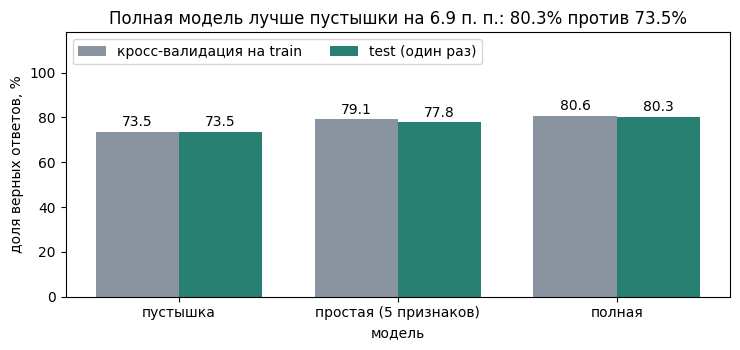

In [33]:
# test трогаем один раз: обучаем на train и считаем accuracy и recall ушедших
final_models = {
    "пустышка": models["пустышка"],
    "простая (5 признаков)": models["простая (5 признаков)"],
    "полная": models[full_name],
}
test_acc, test_recall = {}, {}
for name, (model, cols) in final_models.items():
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    test_acc[name] = accuracy_score(y_test, pred)
    test_recall[name] = recall_score(y_test, pred)

cv_by = {
    "пустышка": cv_results.loc["пустышка", "accuracy, среднее"],
    "простая (5 признаков)": cv_results.loc["простая (5 признаков)", "accuracy, среднее"],
    "полная": cv_results.loc[full_name, "accuracy, среднее"],
}
gap = (test_acc["полная"] - test_acc["пустышка"]) * 100
final_table = pd.DataFrame({
    "accuracy, кросс-валидация": cv_by,
    "accuracy, test": test_acc,
    "доля найденных ушедших, test": test_recall,
}).round(3)
print(final_table)

labels = list(test_acc)
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
b1 = ax.bar(x - 0.19, [cv_by[l] * 100 for l in labels], 0.38, color=GRAY, label="кросс-валидация на train")
b2 = ax.bar(x + 0.19, [test_acc[l] * 100 for l in labels], 0.38, color=TEAL, label="test (один раз)")
ax.bar_label(b1, fmt="%.1f", padding=2)
ax.bar_label(b2, fmt="%.1f", padding=2)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 118)
ax.set_title(f"Полная модель лучше пустышки на {gap:.1f} п. п.: {test_acc['полная'] * 100:.1f}% против {test_acc['пустышка'] * 100:.1f}%")
ax.set_xlabel("модель")
ax.set_ylabel("доля верных ответов, %")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout()
fig.savefig(FIG / "fig6_baseline.png", dpi=130, bbox_inches="tight")
plt.show()
log("test", f"один раз: пустышка {test_acc['пустышка']:.3f}, простая {test_acc['простая (5 признаков)']:.3f}, полная {test_acc['полная']:.3f}", len(X_test))

**Вывод.** Пустышка («никто не уйдёт») даёт 73,5% и на кросс-валидации, и на test. Простая модель (логистическая регрессия на 5 признаках: срок, платёж, договор и оптоволокно) даёт 79,1% на кросс-валидации и 77,8% на test. Полная модель (логистическая регрессия на всех 30 признаках в `Pipeline` со стандартизацией) даёт 80,6% на кросс-валидации и 80,3% на test. Градиентный бустинг (79,7%) не оказался лучше логрегрессии больше чем на разброс (1,4 п. п.), поэтому взята более простая и объяснимая логрегрессия. Test тронут один раз, и он совпал с кросс-валидацией (80,3% против 80,6%): сильного переобучения нет. **Модель лучше пустышки примерно на 7 п. п.** (80,3% против 73,5%). Важнее другое: модель находит 53% ушедших клиентов, а пустышка не находит никого. При этом почти половина ушедших всё равно пропущена, поэтому для отдела удержания это подсказка, а не точный прогноз.

## 14. Выводы

* **Данные почти чистые.** Единственная настоящая проблема это пробел вместо суммы в `TotalCharges` у 11 новых клиентов (`tenure = 0`): это «нет», а не «не знаем», заполнено нулём с флагом. Дублей, невозможных значений и выбросов нет, и это тоже результат проверки.
* **Что связано с оттоком.** Договор (42,7% на помесячном против 2,8% на двухлетнем), срок (53% в первые полгода), оптоволокно (42%) и электронный чек (45%). Пол клиента не важен.
* **Что сработало.** Простая модель на 5 признаках даёт 77,8% на test против 73,5% у пустышки, а все 30 признаков в логрегрессии поднимают результат до 80,3%. Бустинг не стал лучше логрегрессии.
* **Ограничения.** Модель находит около половины (53%) ушедших, а accuracy 80% выглядит лучше, чем есть: не забывайте про пустышку на 73,5%. В данных у ушедших `tenure` и `TotalCharges` заморожены в момент ухода.
* **Что сделал бы дальше.** Подобрать порог вероятности под цену ложной тревоги (скидка не тому клиенту) и цену потерянного клиента, проверить модель на данных, где признаки взяты строго до ухода, и сравнить с ещё одной моделью, например случайным лесом.

## 15. README

README собирается кодом ниже из переменных тетради, поэтому числа в нём всегда совпадают с тетрадью. Пример: часть 9, раздел 9.4.

In [34]:
rate = clean_df[TARGET].mean() * 100
by = lambda col: clean_df.groupby(col)[TARGET].mean() * 100
contract, internet, pay = by("Contract"), by("InternetService"), by("PaymentMethod")
tenure_by = clean_df.groupby(tenure_bins, observed=True)[TARGET].mean() * 100

steps = "\n".join(f"| {k} | {v['решение']} | {v['строк']} |" for k, v in journal.items())
results = "\n".join(
    f"| {n} | {cv_by[n] * 100:.1f}% | {test_acc[n] * 100:.1f}% | {test_recall[n] * 100:.0f}% |" for n in labels
)

readme = f"""# Уйдёт ли клиент телеком-компании? Прогноз оттока на данных Telco

**Задача.** Предсказать по данным о клиенте (услуги, договор, платежи), уйдёт ли он (`Churn`). Классификация, метрика accuracy (доля верных ответов); дополнительно смотрим долю найденных ушедших (recall), потому что пустышка «никто не уйдёт» уже угадывает {100 - rate:.1f}%.

**Данные.** Telco Customer Churn (IBM): [CSV по прямой ссылке]({DATA_URL}). Строк: {raw.shape[0]}, столбцов: {raw.shape[1]}; одна строка это один клиент. Ушли {rate:.1f}% клиентов.

## Что сделано с данными

| шаг | решение | строк |
|---|---|---|
{steps}

## Главное из EDA

* Уходят {rate:.1f}% клиентов, поэтому пустышка «все останутся» даёт {100 - rate:.1f}%.
* Договор: на помесячном уходят {contract['Month-to-month']:.1f}%, на годовом {contract['One year']:.1f}%, на двухлетнем {contract['Two year']:.1f}%.
* Срок: в первые 6 месяцев уходят {tenure_by.iloc[0]:.1f}%, после 4 лет {tenure_by.iloc[-1]:.1f}%.
* Парадокс: с оптоволокном уходят {internet['Fiber optic']:.1f}%, с DSL {internet['DSL']:.1f}%.
* Электронный чек: {pay['Electronic check']:.1f}% ушедших против {pay['Credit card (automatic)']:.1f}-{pay['Bank transfer (automatic)']:.1f}% при автоплатеже.

![Отток по договору](figures/fig2_contract.png)
![Отток по сроку](figures/fig3_tenure.png)

## Утечка

Явной утечки нет. Не берём `customerID` (просто номер: в одиночку модель на нём не лучше пустышки) и саму цель `Churn`. `tenure` и `TotalCharges` берём, но с оговоркой: у ушедших клиентов они заморожены в момент ухода, а `TotalCharges` почти равен `tenure * MonthlyCharges`. Одиночные признаки дают не больше {max(leak_rows['tenure'], leak_rows['TotalCharges'], leak_rows['MonthlyCharges']) * 100:.0f}% точности, это не подозрительно.

## Результаты

| модель | accuracy, кросс-валидация на train | accuracy, test | доля найденных ушедших, test |
|---|---|---|---|
{results}

На test: полная модель ({full_name.split(': ')[-1]}) даёт {test_acc['полная'] * 100:.1f}%, пустышка {test_acc['пустышка'] * 100:.1f}%. Модель лучше пустышки на {gap:.1f} п. п. и находит {test_recall['полная'] * 100:.0f}% ушедших (пустышка не находит никого). Test использован один раз.

![Лестница моделей](figures/fig6_baseline.png)

## Выводы

* Данные почти чистые: единственная проблема это пробел вместо суммы в `TotalCharges` у 11 новых клиентов (`tenure = 0`); это «нет», заполнено нулём с флагом.
* Отток связан с договором, сроком, оптоволокном и электронным чеком (цифры выше); пол клиента не важен.
* Простая модель на 5 признаках даёт {test_acc['простая (5 признаков)'] * 100:.1f}% на test против {test_acc['пустышка'] * 100:.1f}% у пустышки, полная модель {test_acc['полная'] * 100:.1f}%.
* Модель находит {test_recall['полная'] * 100:.0f}% ушедших, то есть около половины пропускает: это подсказка для отдела удержания, а не точный прогноз.
* Дальше: подобрать порог вероятности под цену ложной тревоги и проверить модель на данных, где признаки взяты строго до ухода.

## Как запустить

1. `pip install -r requirements.txt`
2. Открыть `project.ipynb` и выполнить все ячейки (данные скачиваются по ссылке сами).
"""
Path("README.md").write_text(readme, encoding="utf-8")
print(readme)

# Уйдёт ли клиент телеком-компании? Прогноз оттока на данных Telco

**Задача.** Предсказать по данным о клиенте (услуги, договор, платежи), уйдёт ли он (`Churn`). Классификация, метрика accuracy (доля верных ответов); дополнительно смотрим долю найденных ушедших (recall), потому что пустышка «никто не уйдёт» уже угадывает 73.5%.

**Данные.** Telco Customer Churn (IBM): [CSV по прямой ссылке](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv). Строк: 7043, столбцов: 21; одна строка это один клиент. Ушли 26.5% клиентов.

## Что сделано с данными

| шаг | решение | строк |
|---|---|---|
| загрузка | строк: 7043, столбцов: 21 (CSV по ссылке) | 7043 |
| цель в 0 и 1 | Churn: Yes -> 1, No -> 0 | 7043 |
| дубли | полных дублей и повторов customerID нет; без учёта номера совпадают 22 строк, но это разные клиенты: оставляем | 7043 |
| невозможные значения | 7 правил здравого смысла, нарушений нет: ничего не удаляем и не исправляем | 7043 |


## 16. Финальная проверка

`requirements.txt`, «Перезапустить сеанс и выполнить все» без ошибок, тетрадь сохранена с выводами, ссылка открывается в режиме инкогнито. Чек-лист в ТЗ.

In [35]:
from importlib.metadata import version

libs = ["pandas", "numpy", "matplotlib", "scikit-learn"]
Path("requirements.txt").write_text("\n".join(f"{lib}=={version(lib)}" for lib in libs) + "\n", encoding="utf-8")
print(Path("requirements.txt").read_text())

for p in ["README.md", "requirements.txt", "data/telco_clean.csv"]:
    print(p, "есть" if Path(p).exists() else "НЕТ")
print("figures:", sorted(f.name for f in Path("figures").glob("*.png")))

pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
scikit-learn==1.6.1

README.md есть
requirements.txt есть
data/telco_clean.csv есть
figures: ['fig1_target.png', 'fig2_contract.png', 'fig3_tenure.png', 'fig4_internet.png', 'fig5_payment.png', 'fig6_baseline.png']
